cifar-10 图像分类

[kaggle 项目地址](https://www.kaggle.com/datasets/ayush1220/cifar10)

[toronto 官方数据集](https://cave.cs.toronto.edu/kriz/cifar.html)

[torch 官方数据集](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.CIFAR10.html)

[kuangliu/pytorch-cifar](https://github.com/kuangliu/pytorch-cifar)


In [29]:
import copy
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import random_split

# 去除警告
warnings.filterwarnings("ignore")

# 设置全局随机值
torch.manual_seed(23)

In [17]:
# 确定设备
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"当前设备：{device}")

当前设备：mps


In [32]:
# 1、加载数据

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

full_train_set = datasets.CIFAR10(root="../../data/dl", train=True, download=True, transform=transform_train)
# 官方建议从训练集中划分出验证集，因此此处按照 9:1 划分
train_size = int(len(full_train_set) * 0.9)
valid_size = len(full_train_set) - train_size
train_set, valid_set = random_split(full_train_set, [train_size, valid_size], generator=torch.Generator().manual_seed(23))
train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(23))
valid_loader = torch.utils.data.DataLoader(valid_set, batch_size=128, shuffle=False, generator=torch.Generator().manual_seed(23))

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])
test_set = datasets.CIFAR10(root="../../data/dl", train=False, download=True, transform=transform_test)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=64, shuffle=False, generator=torch.Generator().manual_seed(23))

print("训练集数量:", len(train_set))
print("验证集数量:", len(valid_set))
print("测试集数量:", len(test_set))

训练集数量: 45000
验证集数量: 5000
测试集数量: 10000


In [19]:
# 获取第一个批次的数据看看
# - iter()：把可迭代对象转换成迭代器。
# - next()：从迭代器中取出下一个元素。
triandata0 = iter(train_loader)
images, labels = next(triandata0)
print(images.shape, labels.shape)
# torch.Size([128, 3, 32, 32]) 表示批次大小是128，有三个特征图，图片大小是32*32
# torch.Size([128]) 表示有128个目标标签

torch.Size([128, 3, 32, 32]) torch.Size([128])


In [20]:
# 2、定义模型
class CifarCnn(nn.Module):
    def __init__(self, num_classes=10):
        super(CifarCnn, self).__init__()
        self.features = nn.Sequential(
            # block1
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # block2
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # block3
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=64 * 4 * 4, out_features=num_classes), # 64是cnn卷积层最后一层的out_channels， 32 /2 /2 /2 = 4
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# 随机一个特征看看模型定义是否正确
inx = torch.randn(128, 3, 32, 32)
tmodel = CifarCnn()
outx = tmodel(inx)
print(outx.shape) # 预期是[128,10]，128是批量，10是分类数
print(outx[:3, :])


torch.Size([128, 10])
tensor([[-0.7767,  0.4949, -0.2785, -1.1439,  0.3725,  0.8473, -0.7908, -0.0979,
          0.2902,  1.0871],
        [-0.8343,  0.9379, -0.4424, -1.5274,  0.4186,  0.5655, -0.4317, -0.2421,
         -0.8707,  0.6792],
        [-0.8809,  0.5207, -0.1371, -0.7654, -0.2442,  0.5947, -0.2595,  0.1311,
         -0.5365,  0.9489]], grad_fn=<SliceBackward0>)


In [21]:
# 3、训练
print(f"当前使用的设备：{device}")
model = CifarCnn(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss() # 多分类交叉熵损失函数
# optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
# scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
optimizer = torch.optim.SGD(model.parameters(),lr=0.01,momentum=0.9,weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer,step_size=30,gamma=0.1)

train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []

# best_accuracy = float("inf")
best_accuracy = -1.0
best_model_state_dict = None

epochs = 100
for epoch in range(epochs):

    # ==========================
    # 一、训练阶段
    # ==========================
    model.train()
    train_sample = 0
    train_loss_sum = 0
    train_correct = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        # 统计损失
        size = images.shape[0]
        train_sample += size
        train_loss_sum += loss.item() * size

        # 统计正确率
        # # .argmax()的作用是什么？ 返回数据中最大值所在的位置（索引），而不是返回最大值本身。
        predictions = logits.argmax(dim=1)
        train_correct += (predictions == labels.long()).sum().item()

    train_loss = train_loss_sum / train_sample
    train_losses.append(train_loss)
    train_accuracy = train_correct / train_sample
    train_accuracies.append(train_accuracy)


    # ==========================
    # 二、验证阶段
    # ==========================
    model.eval()
    valid_sample = 0
    valid_loss_sum = 0
    valid_correct = 0
    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            size = images.shape[0]
            valid_sample += size
            valid_loss_sum += loss.item() * size
            predictions = torch.argmax(logits, dim=1)
            valid_correct += (predictions == labels.long()).sum().item()

    valid_loss = valid_loss_sum / valid_sample
    valid_losses.append(valid_loss)
    valid_accuracy = valid_correct / valid_sample
    valid_accuracies.append(valid_accuracy)

    # ==========================
    # 三、保存最佳模型
    # ==========================
    if valid_accuracy > best_accuracy:
        best_accuracy = valid_accuracy
        best_model_state_dict = copy.deepcopy(model.state_dict())


    # ==========================
    # 四、调整学习率
    # ==========================
    # 每一个 epoch 完成之后调整学习率
    scheduler.step()

    # 获取当前学习率
    current_lr = optimizer.param_groups[0]["lr"]

    # ==========================
    # 五、打印训练结果
    # ==========================
    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch+1}, LR: {current_lr:.6f}, train_loss: {train_loss:.4f}, valid_loss: {valid_loss:.4f}, train_accuracy: {train_accuracy:.4f}, valid_accuracy: {valid_accuracy:.4f}")


torch.save(best_model_state_dict, "../../data/output/CifarCnn_best_model_state_dict.pth")
# print(f"CifarCnn_best_model_state_dict: {best_model_state_dict}")
print(best_model_state_dict.keys())
print(f"best_accuracy: {best_accuracy}")


当前使用的设备：mps
epoch: 9, LR: 0.010000, train_loss: 0.7756, test_loss: 0.7262, train_accuracy: 0.7287, test_accuracy: 0.7484
epoch: 19, LR: 0.010000, train_loss: 0.6790, test_loss: 0.6583, train_accuracy: 0.7635, test_accuracy: 0.7724
epoch: 29, LR: 0.001000, train_loss: 0.6318, test_loss: 0.6533, train_accuracy: 0.7814, test_accuracy: 0.7738
epoch: 39, LR: 0.001000, train_loss: 0.5494, test_loss: 0.5691, train_accuracy: 0.8111, test_accuracy: 0.8071
epoch: 49, LR: 0.001000, train_loss: 0.5453, test_loss: 0.5689, train_accuracy: 0.8116, test_accuracy: 0.8035
epoch: 59, LR: 0.000100, train_loss: 0.5388, test_loss: 0.5648, train_accuracy: 0.8130, test_accuracy: 0.8074
epoch: 69, LR: 0.000100, train_loss: 0.5232, test_loss: 0.5557, train_accuracy: 0.8206, test_accuracy: 0.8109
epoch: 79, LR: 0.000100, train_loss: 0.5222, test_loss: 0.5570, train_accuracy: 0.8211, test_accuracy: 0.8109
epoch: 89, LR: 0.000010, train_loss: 0.5266, test_loss: 0.5533, train_accuracy: 0.8186, test_accuracy: 0.8101

In [34]:
# 测试阶段
model.eval()
test_sample = 0
test_loss_sum = 0
test_correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        size = images.shape[0]
        test_sample += size
        test_loss_sum += loss.item() * size
        predictions = torch.argmax(logits, dim=1)
        test_correct += (predictions == labels.long()).sum().item()

test_loss = test_loss_sum / test_sample
test_accuracy = test_correct / test_sample
print(f"test_accuracy: {test_accuracy:.4f}, test_loss: {test_loss:.4f}")

test_accuracy: 0.8119, test_loss: 0.5531


In [23]:

import json
data = {
    "train_losses": train_losses,
    "test_losses": test_losses,
    "train_accuracies": train_accuracies,
    "test_accuracies": test_accuracies,
}

# 保存到文件
with open("./../../data/output/training_data.json", "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=4)


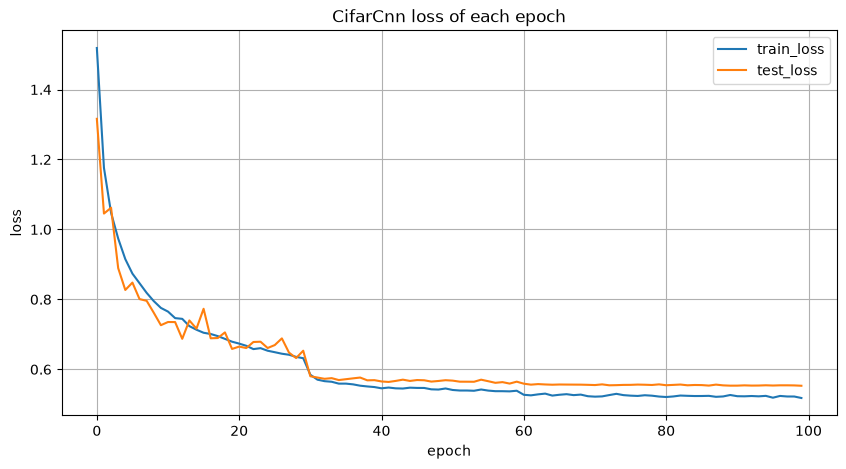

In [27]:
# 训练过程可视化（loss 曲线）
# 1 定义图片大小
plt.figure(figsize=(10, 5))

# 2 添加两条曲线数据
plt.plot(train_losses, label="train_loss")
plt.plot(valid_losses, label="valid_loss")

# 定义横纵坐标和图片标题
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("CifarCnn loss of each epoch") # The loss of each epoch for Cifar CNN network
plt.legend() # 显示图列
plt.grid(True) # 显示网格
plt.show() # 显示图片


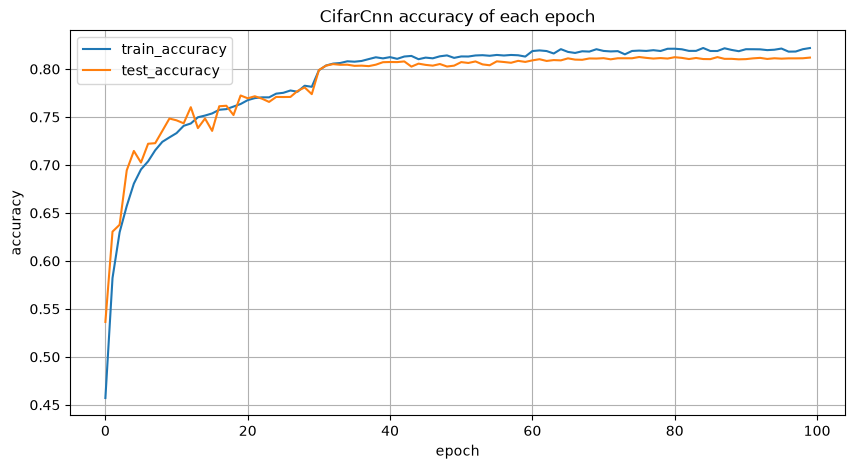

In [28]:

# 训练过程可视化（acc 曲线）
# 定义图片尺寸
plt.figure(figsize=(10, 5))

# 添加曲线数据
plt.plot(train_accuracies, label="train_accuracy")
plt.plot(valid_accuracies, label="valid_accuracy")

# 添加坐标轴和标题
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("CifarCnn accuracy of each epoch")

# 显示图片
plt.legend()
plt.grid(True)
plt.show()


In [9]:
# 读取训练数据来进行可视化展示
# （类似在GPU服务器上训练了数据，但是服务器不能展示数据(loss/acc/correct)，因此在服务器训练的时候先保存每个epoch训练数据(日志)，等待训练完成之后在本地展示分析）
import json
import matplotlib.pyplot as plt
# 读取 JSON 文件
with open("./../../data/output/training_data-197.json", "r", encoding="utf-8") as f:
    loaded_data = json.load(f)
train_losses = loaded_data["train_losses"]
valid_losses = loaded_data["valid_losses"]
train_accuracies = loaded_data["train_accuracies"]
valid_accuracies = loaded_data["valid_accuracies"]
test_accuracy = loaded_data["test_accuracy"]
print(f"测试正确率：{test_accuracy:.4f}")

测试正确率：0.8362


In [ ]:
# 画 损失loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="train_loss")
plt.plot(valid_losses, label="valid_loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("CifarCnn loss of each epoch")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 画 正确率acc
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies, label="train_accuracy")
plt.plot(valid_accuracies, label="valid_accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("CifarCnn accuracy of each epoch")
plt.legend()
plt.grid(True)
plt.show()
